# Predicting Annual Revenue of Rural Water Infrastructure in Africa

## 1. Introduction

### Mission Statement
To leverage software engineering and data-driven technologies to promote transparency, accountability, and efficient public service delivery, contributing to efforts to combat corruption and strengthen good governance in Uganda and across Africa.

### Problem Statement
Rural water service providers often face challenges in estimating the revenue generated by their infrastructure, making financial planning and resource allocation difficult [1], [2]. Without reliable estimates, it becomes challenging to plan for infrastructure maintenance, operational costs, and sustainable water service delivery [3]. Using machine learning to estimate annual water-service revenue based on infrastructure characteristics, population served, and revenue collection methods could support informed decision making and financial accountability.

### Project Objectives
- Exploring and preprocessing rural water infrastructure data to identify factors influencing annual revenue.
- Developing and comparing four regression models: SGDRegressor, Linear Regression, Decision Tree, and Random Forest.
- Evaluating model performance using Mean Squared Error (MSE) and selecting the best performing model.
- Deploying the selected model through a public FastAPI service on Render, supporting predictions and retraining.
- Developing a Flutter mobile application that allows users to input infrastructure characteristics and obtain estimated annual revenue.

### Intended Users
- Water service operators
- Public infrastructure planners

### Dataset Overview
- Source: [Dryad](https://datadryad.org/dataset/doi:10.5061/dryad.7pvmcvf7r)
- Dataset Name: Revenue and investment data for rural drinking water infrastructure in Africa 2021-2024
- Author: Duncan McNicholl, University of Oxford
- Geographical coverage: 11 African countries
- Period: 2021-2024
- Observations: 11,957
- Columns: 44
- Target variable: wp_revenue_USD

### References
[1] D. McNicholl, E. Aydinsoy, and R. Hope, “Africa’s water revenue paradox,” Research Square, preprint, Mar. 2026, doi: 10.21203/rs.3.rs-8878999/v1.

[2] A. M. Armstrong, “Revenue patterns of piped water services in rural Africa,” D.Phil. dissertation, Univ. of Oxford, Oxford, U.K., 2022, doi: 10.5287/ora-2r7vvmmpb.

[3] D. S. G. Agueh, “Financing water and sanitation in Africa: Resilience, reuse, ecosystems, decentralised services and water diplomacy,” RFLD, Oct. 9, 2026. [Online]. Available: https://rflgd.org/financing-water-sanitation-africa-gloria-agueh/.


## 2. Data Loading and Initial Inspection

## 2.1 Importing libraries

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2.2 Loading dataset

In [11]:
df = pd.read_csv('data/analysis_dataset.csv')

## 2.3 Initial dataset inspection

In [12]:
print(df.shape) # Confirming dataset dimensions

df.head() # Previewing first 5 observations

df.info() # Inspecting data types and non-null counts

df.describe() # Examining numerical distributions

(11957, 44)
<class 'pandas.DataFrame'>
RangeIndex: 11957 entries, 0 to 11956
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   year                           11957 non-null  int64  
 1   lat                            11957 non-null  float64
 2   lon                            11957 non-null  float64
 3   num_taps                       11957 non-null  int64  
 4   num_hh                         11957 non-null  int64  
 5   wp_pop_last                    11957 non-null  int64  
 6   num_kiosks                     8071 non-null   float64
 7   num_scheme_tanks               3561 non-null   float64
 8   wp_revenue_model               11525 non-null  str    
 9   volume_method                  8071 non-null   str    
 10  country_name                   11957 non-null  int64  
 11  wp_m3                          11957 non-null  float64
 12  wp_revenue_USD                 11957 non-null

,year,lat,lon,num_taps,num_hh,wp_pop_last,num_kiosks,num_scheme_tanks,country_name,wp_m3,...,pop_served_last_within_2000m,pop_served_last_within_5000m,pop_served_last_within_10000m,pop_served_last_within_20000m,Population_Within_500m,Population_Within_1000m,Population_Within_2000m,Population_Within_5000m,Population_Within_10000m,Population_Within_20000m
count,11957.000000,11957.0,11957.0,11957.000000,11957.000000,11957.000000,8071.000000,3561.000000,11957.000000,11957.000000,...,11891.000000,11891.000000,11891.000000,11891.000000,11898.000000,11898.000000,11898.000000,11898.000000,1.189800e+04,1.189800e+04
mean,2022.837585,0.0,0.0,0.556410,3.582086,788.350924,0.065549,0.019938,4.405620,992.753307,...,7750.337987,20905.691111,44119.843916,79195.244302,937.563018,2226.958525,5108.264345,18034.726023,5.772356e+04,1.972405e+05
std,0.879613,0.0,0.0,2.285919,32.862670,1645.037532,1.234582,0.156851,3.419542,3051.982047,...,14058.411701,36377.288084,68471.814265,87777.140270,1470.087582,3714.054648,9035.857821,36338.479652,1.025141e+05,2.927969e+05
min,2021.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,2022.000000,0.0,0.0,0.000000,0.000000,197.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,1878.000000,8020.000000,23804.000000,192.680252,453.261508,1004.266962,3304.601272,1.104608e+04,3.589454e+04
50%,2023.000000,0.0,0.0,0.000000,0.000000,282.000000,0.000000,0.000000,3.000000,0.000000,...,2000.000000,7880.000000,22560.000000,53356.000000,451.838684,998.909635,2575.468561,10689.994140,3.172623e+04,7.608601e+04
75%,2024.000000,0.0,0.0,0.000000,0.000000,672.000000,0.000000,0.000000,9.000000,982.800000,...,7784.000000,20738.000000,47560.000000,98786.000000,1080.684444,2292.966191,5547.358155,21419.958132,6.562891e+04,2.458513e+05
max,2024.000000,0.0,0.0,44.000000,888.000000,23708.000000,44.000000,3.000000,10.000000,76673.120000,...,141960.000000,252457.000000,402122.000000,421365.000000,25361.761850,74163.978840,246267.334600,815807.769200,1.828080e+06,3.338384e+06


## 2.4 Initial observations
- The dataset contains 11,957 observations and 44 columns, covering 2021-2024.
- It includes numerical and categorical features representing rural water infrastructure.
- The target variable is wp_revenue_USD, representing annual revenue in USD.
- Some columns contain missing values that will require preprocessing.
- The latitude and longitude columns are anonymized for confidentiality.
- The twelve monthly variables contain no numerical variation.

## 3. Exploratory Data Analysis
This section investigates revenue distribution, differences between infrastructure types, relationships between variables, and potential data-quality issues that could influence the training of the model

## 3.1 Distribution of Annual Water Service Revenue

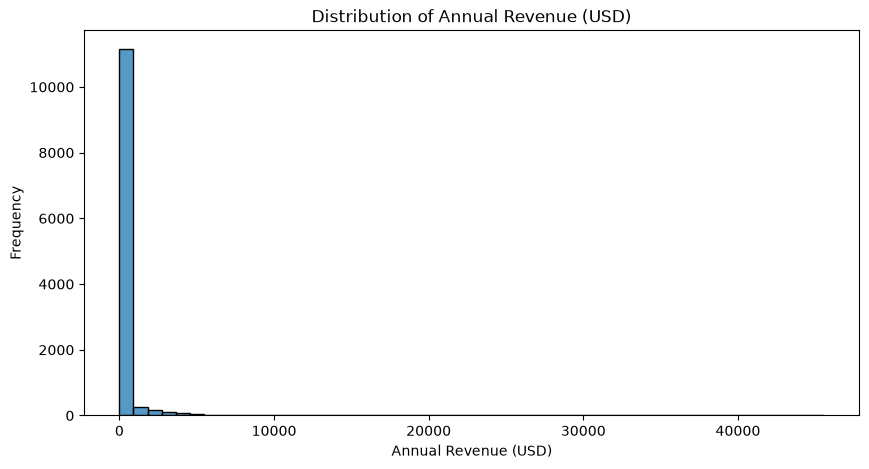

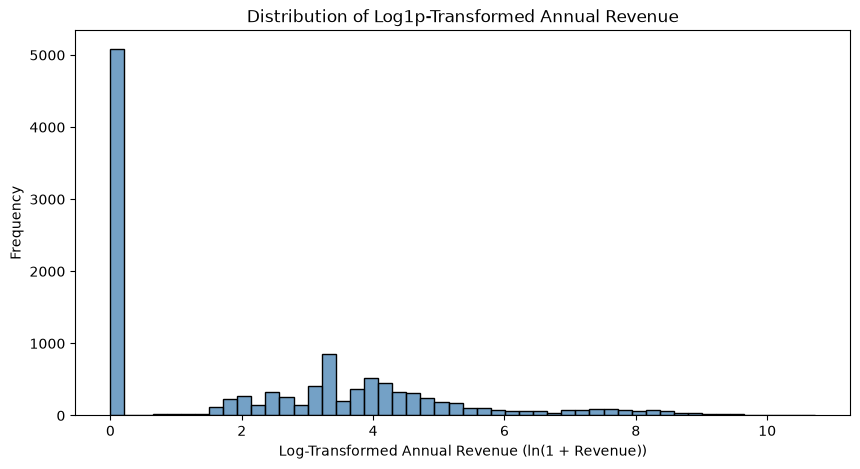

In [13]:
# Histograms comparing annual revenue distribution (USD)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="wp_revenue_USD",
    bins=50,
    kde=False
)

plt.title("Distribution of Annual Revenue (USD)")
plt.xlabel("Annual Revenue (USD)")
plt.ylabel("Frequency")
plt.show()

# Log transformed revenue histogram
# Log transformation makes it easier to see the distribution of smaller values while retaining zero revenues
log_revenue = np.log1p(df["wp_revenue_USD"])

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x=log_revenue, bins=50, kde=False, color="steelblue")

plt.title("Distribution of Log1p-Transformed Annual Revenue")
plt.xlabel("Log-Transformed Annual Revenue (ln(1 + Revenue))")
plt.ylabel("Frequency")

plt.show()

## Interpretation of revenue distribution

### Graph 1 - Distribution of Annual Revenue (USD)
### Main takeaway and modelling implications
The revenue distribution is heavily right-skewed, with most water infrastructure systems generating relatively low annual revenue. A small portion of systems generate significantly higher revenue, creating a right long tail (≈$45,562). The extreme differences in revenue could affect model performance since MSE heavily penalizes large prediction errors.

### Graph 2 - Distribution of Log1p-Transformed Annual Revenue
### Main takeaway and modelling implications
The logarithmic transformation was used to better understand the distribution through compressing large revenue values, into smaller values. A prominent spike remains at zero, reflecting how 5,084 observations (42.5%) recorded no annual revenue. These zero revenue observations represent a substantial part of the dataset and should not automatically be removed.

## 3.2 Revenue Comparison by Infrastructure Type

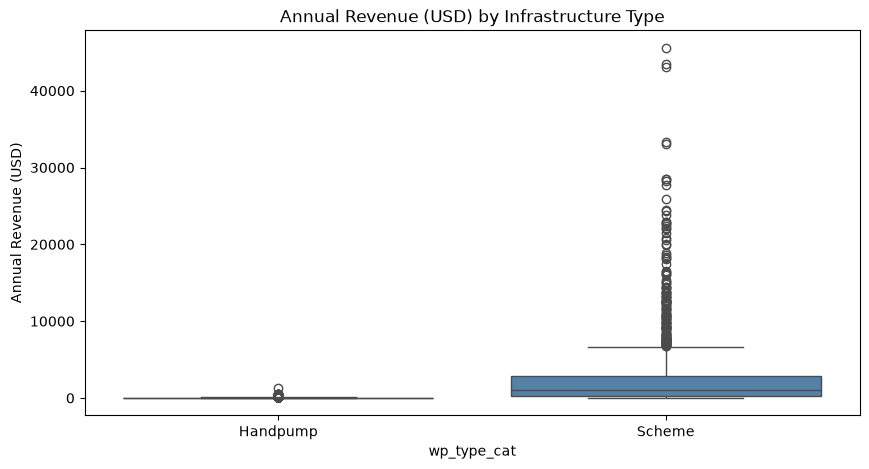

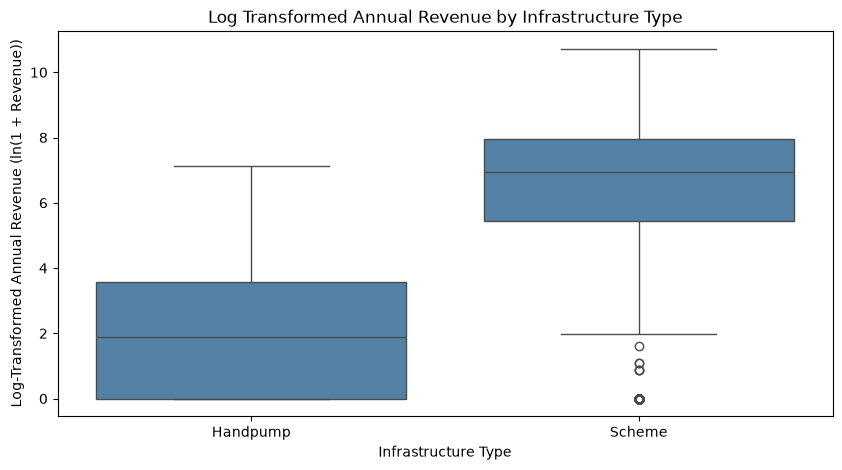

In [14]:
# Box plots comparing the revenue distributions (USD) of the two infrastructure types

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="wp_type_cat", y="wp_revenue_USD", color="steelblue")

plt.title("Annual Revenue (USD) by Infrastructure Type")
plt.ylabel("Annual Revenue (USD)")

plt.show()

# Log transformed boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="wp_type_cat", y=log_revenue, color="steelblue")

plt.title("Log Transformed Annual Revenue by Infrastructure Type")
plt.xlabel("Infrastructure Type")
plt.ylabel("Log-Transformed Annual Revenue (ln(1 + Revenue))")

plt.show()

## Interpretation of boxplots

### Graph 1 - Distribution of Annual Revenue (USD) by Infrastructure Type
### Main takeaway and modelling implications
Water schemes generate significantly higher annual revenue than handpumps. Schmes also have a greater spread in revenue with several outliers reaching ≈$45,562. The difference in revenue scale indicates that infrastructure type (wp_type_cat) is an important variable to consider when predicting annual revenue.


### Graph 2 - Distribution of Log1p-Transformed Annual Revenue by Infrastructure Type
### Main takeaway and modelling implications
Water schemes have a noticeably higher median revenue ($1,028) than handpumps ($5.57). The lower quartile of handpump revenue is zero, reflecting significant number of handpumps that generate no revenue. The observation encourages the evaluation of model performance separately for handpumps and schemes, since overall MSE may be dominated by the much larger scheme revenue, if handled together.


## 3.3 Correlation Heatmap

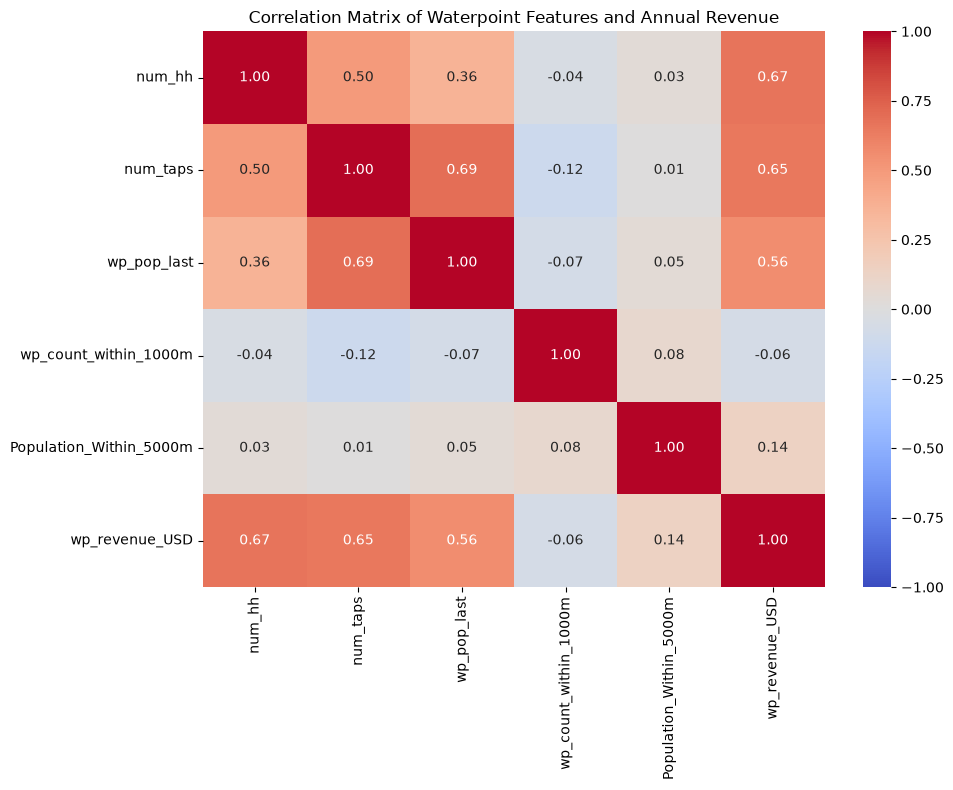

In [15]:
# Correlation heatmap of numerical predictors and the revenue target

cols = [
    "num_hh",
    "num_taps",
    "wp_pop_last",
    "wp_count_within_1000m",
    "Population_Within_5000m",
    "wp_revenue_USD",
]

# Calculation of the correlation matrix
corr_matrix = df[cols].corr()

# Plotting the heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,  # Display correlation values inside each cell
    fmt=".2f",  # Round numbers to 2 decimal places for readability
    cmap="coolwarm",  # Diverging color scheme (blue = negative, red = positive)
    vmin=-1,  # Anchor color scale minimum at -1
    vmax=1,  # Anchor color scale maximum at 1
    center=0,  # Set neutral color midpoint at 0
)

plt.title("Correlation Matrix of Waterpoint Features and Annual Revenue")
plt.tight_layout()

plt.show()

## Interpretation of correlation map
The number of households (num_hh), number of taps (num_taps), and population served (wp_pop_last) show the strongest positive relationships with annual revenue. This suggests that larger water supply systems serving more households and people tend to generate higher revenue, and that more taps tend to serve larger populations indicating potiential multicollinearity. Households, taps, and population served are promising numerical predictors, whereas the weaker predictors shall initially be retained because they may capture nonlinear relationships that Decision Tree and Random Forest models can exploit.

## 3.4 Scatterplot (Before Model Training)

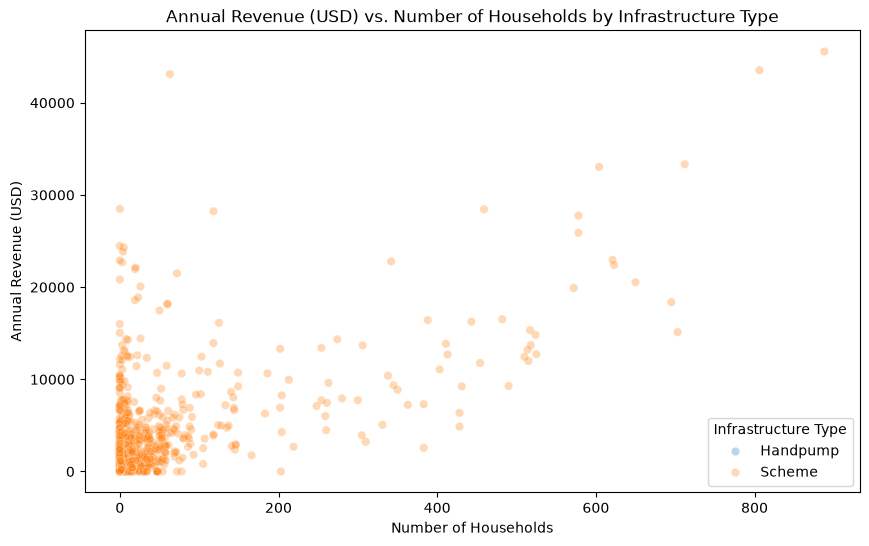

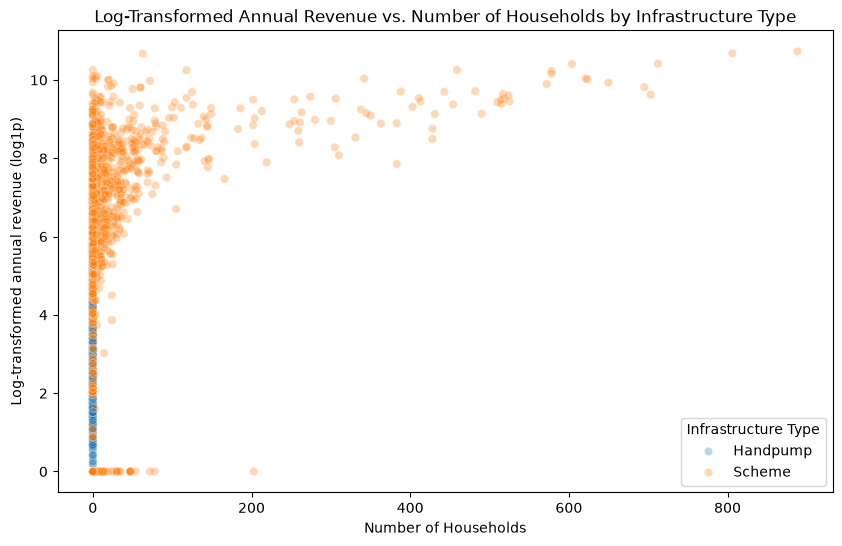

In [16]:
# Scatterplot of the most strongly correlated eligible numerical predictors against revenue

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="num_hh", y="wp_revenue_USD", hue="wp_type_cat", alpha=0.3)

plt.title("Annual Revenue (USD) vs. Number of Households by Infrastructure Type")
plt.xlabel("Number of Households")
plt.ylabel("Annual Revenue (USD)")
plt.legend(title="Infrastructure Type")

plt.show()

# Log transformed scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="num_hh", y=log_revenue, hue="wp_type_cat", alpha=0.3)

plt.title("Log-Transformed Annual Revenue vs. Number of Households by Infrastructure Type")
plt.xlabel("Number of Households")
plt.ylabel("Log-transformed annual revenue (log1p)")
plt.legend(title="Infrastructure Type")

plt.show()



## Interpretation of scatter plot (before training)
The plot shows a general positive relationship between the number of households and annual revenue. Handpump observations remain concentrated at low household counts and revenue levels, while schemes are more widely spread across higher household counts and higher revenues. Many observations are clustered at very low household counts, especially near zero, which suggests that the dataset contains many small-scale systems, and that relationship between households and revenue is not perfectly linear across the full range.

## 4 Data Preparation and Feature Selection

### 4.1 Feature Selection

In [17]:
# Definition of the eight selected predictor columns
predictors = [
    'wp_type_cat',
    'wp_revenue_model',
    'volume_method',
    'num_hh',
    'num_taps',
    'wp_pop_last',
    'wp_count_within_1000m',
    'Population_Within_5000m'
]

# Definition of the target variable separately
target = 'wp_revenue_USD'

# Creation of new dataframe only containing the nine columns
model_df = df[predictors + [target]].copy()

# Shape and column verification of the new data
print("New DataFrame shape:", model_df.shape)
model_df.head()

New DataFrame shape: (11957, 9)


,wp_type_cat,wp_revenue_model,volume_method,num_hh,num_taps,wp_pop_last,wp_count_within_1000m,Population_Within_5000m,wp_revenue_USD
0,Handpump,waterpoint,estimated,0,0,540,2,16765.475450,0.00
1,Handpump,waterpoint,NaN,0,0,275,0,6819.277203,105.84
2,Handpump,waterpoint,NaN,0,0,185,0,3808.431144,227.53
3,Handpump,waterpoint,NaN,0,0,200,0,5872.281555,12.96
4,Handpump,waterpoint,NaN,0,0,180,0,11283.372050,92.74


## Justification of feature exclusions

| Excluded columns | Reason |
| --- | --- |
| lat, lon | Anonymized placeholders (privacy/contractual reasons) |
| month_1 – month_12 | All non-missing values are zero |
| num_scheme_tanks | Approximately 70% missing |
| num_kiosks | Significant missingness and not essential to the model |
| wp_m3 | Uncertain whether actual water volume is available at prediction time |
| country_name | Encoded country labels without a verified mapping for app users |
| quarters_used | Unclear reporting-period information |
| year | The model estimates revenue from infrastructure types rather than forecasting future years |
| other population and waterpoint radius columns | Risk of introducing redundant information and calculations |

## 4.2 Missing value handling

In [18]:
# Calculating missing value counts per column
missing_count = model_df.isna().sum()

# Calculating percentage of missing values
missing_percent = (missing_count / len(model_df)) * 100

# Combining into a three column summart table
missing_summary = pd.DataFrame({
    'Column': model_df.columns,
    'Missing Count': missing_count.values,
    'Missing Percentage (%)': missing_percent.values.round(2)
})

# Sorting the table from highest to lowest in terms of missingness
missing_summary = missing_summary.sort_values(by='Missing Count', ascending=False).reset_index(drop=True)
display(missing_summary)

,Column,Missing Count,Missing Percentage (%)
0,volume_method,3886,32.50
1,wp_revenue_model,432,3.61
2,Population_Within_5000m,59,0.49
3,wp_type_cat,0,0.00
4,num_hh,0,0.00
5,num_taps,0,0.00
6,wp_pop_last,0,0.00
7,wp_count_within_1000m,0,0.00
8,wp_revenue_USD,0,0.00


## Missing value handling strategy

| Feature | Handling stragey | Justification|
| --- | --- | --- |
| wp_revenue_model | Replacing missing values with Unknown | Avoiding assuming a particular payment model |
| volume_method | Replacing missing values with Unknown | Preserving observations without assuming a measurement method |
| Population_Within_5000m | Median imputation | Very few missing values; median less sensitive to extreme values |

## Interpretation of missing value handling
- Only three of the eight selected predictors contain missing values
- volume_method has the highest missingness at 32.5%, so dropping incomplete rows would result into significant data loss
- Using unknown category for categorical values and median imputation for numerical values allows retaining of more observations without making unnecessary assumptions

## 4.3 Definition of predictors and target

## 4.4 Train-test split

## 4.5 Preprocessing pipeline